In [1]:
import numpy as np
from astropy.io import fits
 
import matplotlib.pyplot as plt

from joblib import Parallel, delayed

import scipy.ndimage as nd
from spectral_cube import SpectralCube

/Users/thummimm/miniconda3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
co_cube = fits.open('../../data/maps/m33_all_co21_8p0as.K.fits')[0].data

In [3]:
zeroth_moment = lambda n, array: np.nansum(array,axis=n)

In [ ]:
# co_cube_pos = co_cube*(co_cube>0)

In [4]:
moments0 = Parallel(n_jobs=3)(delayed(zeroth_moment)(n,co_cube) for n in range(3))

In [5]:
moments0_ser = [zeroth_moment(n,co_cube) for n in range(3)]

In [ ]:
#from 10/02 lglbs meeting: 
#the negative values are noise
#use the primary beam weight map -- or a noise map

#

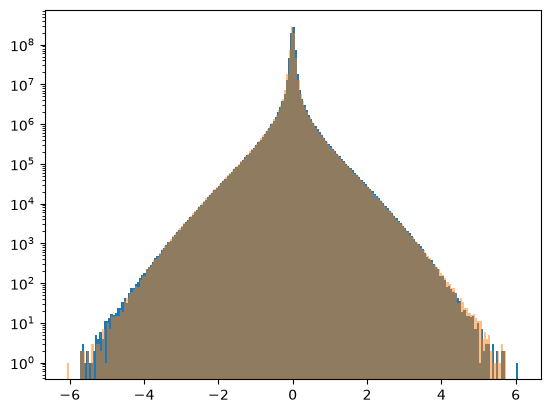

In [7]:
plt.hist(np.ravel(co_cube),bins=200)
plt.hist(np.ravel(-co_cube),bins=200,alpha=0.5)

plt.yscale('log')
plt.show()

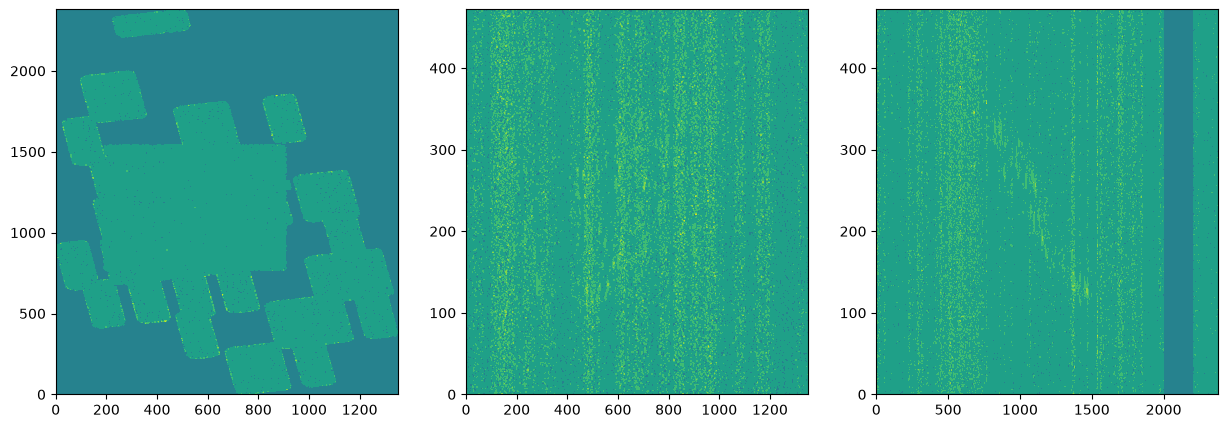

In [8]:
fig,axs = plt.subplots(1,3,figsize=(15,5))
[(
axs[i].contourf(mom_map, ),

)for i,mom_map in enumerate(moments0)]
plt.show()


In [1]:
# below is code from erik on how to remove the edges

In [9]:
co_cube_spectral = SpectralCube.read('../../data/maps/m33_all_co21_8p0as.K.fits') 

In [10]:
co_cube_spectral.allow_huge_operations=True

In [11]:
maxmap = co_cube_spectral.max(axis=0)

/Users/thummimm/miniconda3/lib/python3.12/site-packages/spectral_cube-0.6.7-py3.12.egg/spectral_cube/spectral_cube.py:538: RuntimeWarning: All-NaN slice encountered
  result = function(np.dstack((result, plane)), axis=2, **kwargs)


In [12]:
maxmap.shape

(2381, 1351)

In [13]:
# maxmap now has NaN values everywhere that there are bad data along a spectral axis
gooddata = np.isfinite(maxmap)

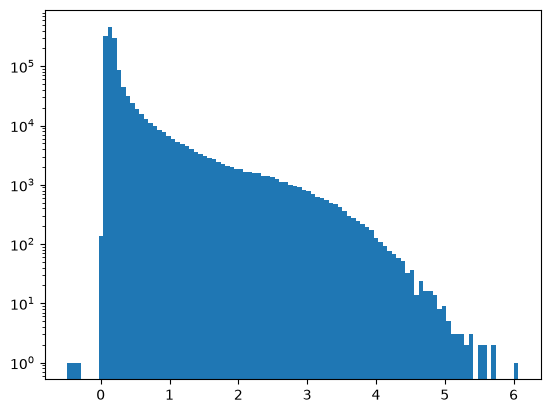

In [17]:
plt.hist(np.ravel(maxmap),bins=100)
plt.yscale('log')

TypeError: Cannot use ufunc 'logical_or' with quantities

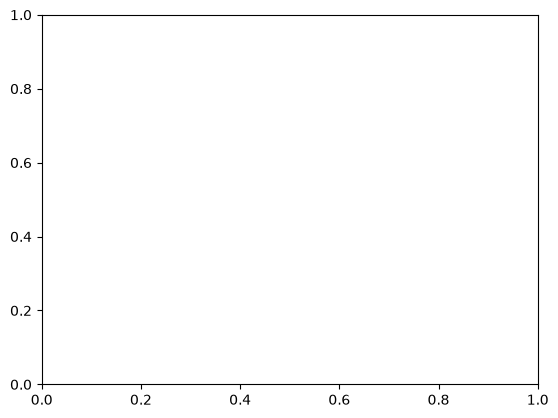

In [15]:
plt.contourf(maxmap)

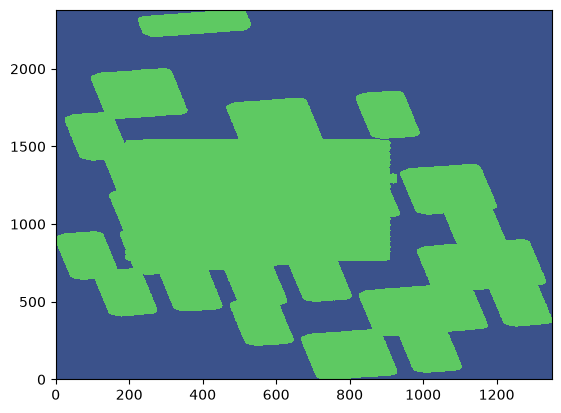

In [14]:
plt.contourf(gooddata)

In [31]:
# now we use erosion to shrink the map away from the edges
# We need a structuring element to shrink by a radius "r".  This blanks pixels within 10 of an edge
r = 5 # beam fwhm = 5 pixels (calculated from header) 10
yy, xx = np.meshgrid(np.arange(2*r+1)-r, np.arange(2*r+1)-r)
elt = yy**2 + xx**2 < r**2
eroded_mask_r5 = nd.binary_erosion(gooddata, elt)


r = 10
yy, xx = np.meshgrid(np.arange(2*r+1)-r, np.arange(2*r+1)-r)
elt = yy**2 + xx**2 < r**2
eroded_mask_r10 = nd.binary_erosion(gooddata, elt)

In [19]:
# This is a 2D mask. We can apply this to the 3D cube
co_cube_r5_erosion  = co_cube_spectral.with_mask(eroded_mask_r5[np.newaxis, :, :])
co_cube_r10_erosion = co_cube_spectral.with_mask(eroded_mask_r10[np.newaxis, :, :])

In [20]:
moments_r5  = [zeroth_moment(n,co_cube_r5_erosion) for n in range(3)] 
moments_r10 = [zeroth_moment(n,co_cube_r10_erosion) for n in range(3)] 

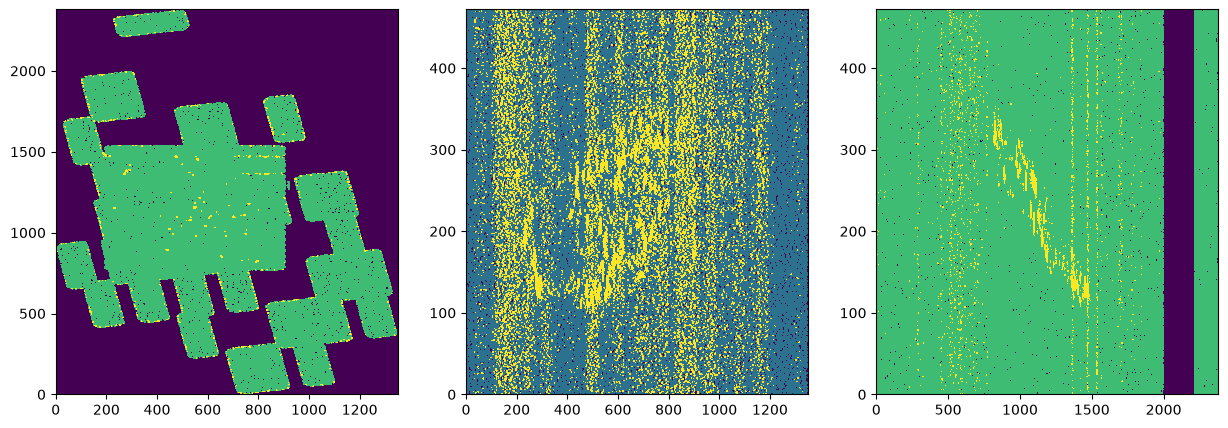

In [26]:
fig,axs = plt.subplots(1,3,figsize=(15,5))
[(
axs[i].contourf(mom_map, vmin=2,vmax=10),

)for i,mom_map in enumerate(moments_r5)]
plt.show()


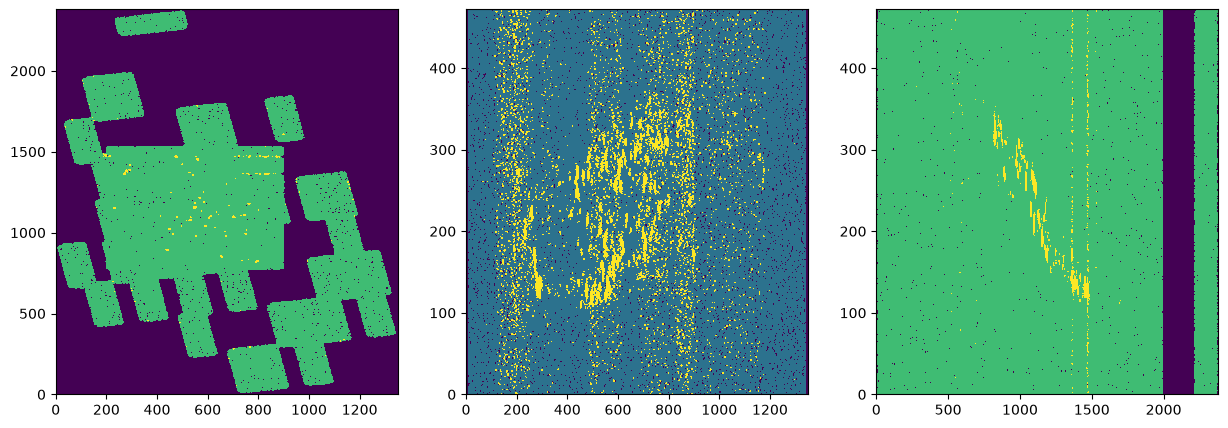

In [27]:
fig,axs = plt.subplots(1,3,figsize=(15,5))
[(
axs[i].contourf(mom_map, vmin=2,vmax=10),

)for i,mom_map in enumerate(moments_r10)]
plt.show()


In [29]:
r = 15
yy, xx = np.meshgrid(np.arange(2*r+1)-r, np.arange(2*r+1)-r)
elt = yy**2 + xx**2 < r**2
eroded_mask_r15 = nd.binary_erosion(gooddata, elt)

In [30]:
co_cube_r15_erosion = co_cube_spectral.with_mask(eroded_mask_r15[np.newaxis, :, :])

In [32]:
moments_r15 = [zeroth_moment(n,co_cube_r15_erosion) for n in range(3)] 

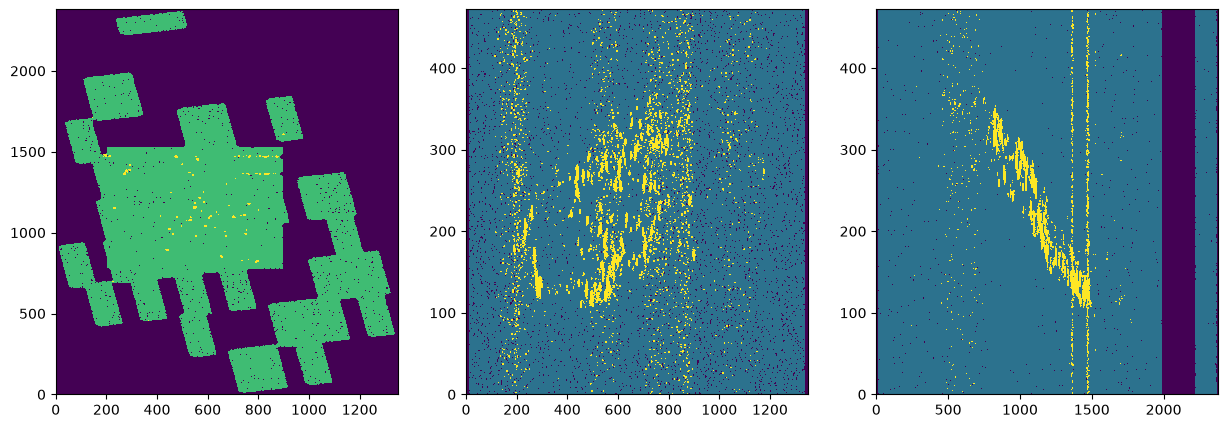

In [33]:
fig,axs = plt.subplots(1,3,figsize=(15,5))
[(
axs[i].contourf(mom_map, vmin=2,vmax=10),

)for i,mom_map in enumerate(moments_r15)]
plt.show()


In [36]:
for n,cube in zip([15,10,5],[co_cube_r15_erosion, co_cube_r10_erosion, co_cube_r5_erosion]):
    np.save(f'm33_co21_8p0as_eroded_r{n}.npy',cube)

In [ ]:
#code in cell below is to make noise map

In [ ]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

F = '/Users/thummimm/Documents/research/data/maps/m33_all_co21_8p0as.K.fits'
FGND_CHAN = 0       # channels to skip at the start (60 for the HI mid-res cube)
ROWS = 30           # sky rows per chunk, to keep memory small
MIN_NEG = 20        # need this many negative voxels along a spectrum to trust sigma

with fits.open(F, memmap=True) as h:
    d = h[0].data
    nv, ny, nx = d.shape
    sigma = np.full((ny, nx), np.nan, dtype=np.float32)
    for j in range(0, ny, ROWS):
        v = np.asarray(d[FGND_CHAN:, j:j + ROWS, :], dtype=np.float32)   # (channels, rows, nx)
        neg = np.where(v < 0, -v, np.nan)                                 # |negative values| only
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)
            s = np.nanmedian(neg, axis=0) / 0.6745       # half-Gaussian: median|v| = 0.6745 sigma
        s[np.sum(np.isfinite(neg), axis=0) < MIN_NEG] = np.nan
        sigma[j:j + ROWS] = s

fig, ax = plt.subplots(figsize=(6.5, 7), constrained_layout=True)
im = ax.imshow(sigma, origin='lower', cmap='magma',
               vmin=np.nanpercentile(sigma, 1), vmax=np.nanpercentile(sigma, 99))
fig.colorbar(im, ax=ax, shrink=0.7, label=r'$\sigma$ [K]')
ax.set_title(f'per-pixel noise (channels {FGND_CHAN}+; negative-side median/0.6745)')
ax.set_xlabel('x [pix]'); ax.set_ylabel('y [pix]')
plt.show()


In [ ]:
import astropy.units as u
from astropy.wcs.utils import proj_plane_pixel_scales


def beam_fwhm_pix(cube):
    """Beam major-axis FWHM of a SpectralCube, in pixels."""
    pix = proj_plane_pixel_scales(cube.wcs.celestial)[0] * u.deg
    return float((cube.beam.major / pix).to_value(u.dimensionless_unscaled))


def erode_cube(cube, n, gooddata=None):
    """Mask the edges of `cube` by binary erosion of its good-data footprint.

    n         : radius of the disk structuring element, in beam FWHMs
    gooddata  : optional precomputed 2D footprint (np.isfinite(cube.max(axis=0))),
                so repeated calls don't redo the max over the whole cube
    Returns a SpectralCube sharing the data of `cube` with the eroded 2D mask applied.
    """
    if gooddata is None:
        gooddata = np.isfinite(cube.max(axis=0))
    r = n * beam_fwhm_pix(cube)                  # radius in pixels
    k = int(np.ceil(r))
    yy, xx = np.meshgrid(np.arange(-k, k + 1), np.arange(-k, k + 1))
    elt = yy**2 + xx**2 < r**2                   # same criterion as the original cell
    eroded_mask = nd.binary_erosion(gooddata, elt)
    return cube.with_mask(eroded_mask[np.newaxis, :, :])


In [4]:
def zeroth_moments(cube):
    """Sum of the (masked) cube along each of its three axes -> list of 3 2D arrays."""
    return [np.asarray(cube.sum(axis=a).value) for a in range(3)]


def plot_erosion(cube, eroded, n, mom_orig=None, savepath=None):
    """3 rows x 2 cols: row = zeroth moment along axis 0/1/2; col 0 original, col 1 eroded.
    Pass `mom_orig` (from zeroth_moments) to avoid re-summing the original cube."""
    if mom_orig is None:
        mom_orig = zeroth_moments(cube)
    mom_ero = zeroth_moments(eroded)
    labels = ['axis 0 (spectral): sum over v', 'axis 1: sum over y', 'axis 2: sum over x']

    fig, axes = plt.subplots(3, 2, figsize=(9, 14), constrained_layout=True)
    for row, (mo, me, lab) in enumerate(zip(mom_orig, mom_ero, labels)):
        vmin, vmax = np.nanpercentile(mo, [1, 99.5])      # shared scale across the row
        for col, (m, name) in enumerate([(mo, 'original'), (me, f'eroded, n = {n} beam')]):
            im = axes[row, col].imshow(m, origin='lower', vmin=vmin, vmax=vmax,
                                       cmap='viridis', aspect='auto' if row else 'equal')
            axes[row, col].set_title(f'{lab}\n{name}', fontsize=9)
        fig.colorbar(im, ax=axes[row, :], shrink=0.8, label='K (summed channels/pixels)')
    if savepath:
        fig.savefig(savepath, dpi=120)
    plt.show()
    return fig


In [7]:
# `cube` above was already overwritten with the n=1 eroded version, so reload the original
cube_full = SpectralCube.read('../../data/maps/m33_all_co21_8p0as.K.fits')
cube_full.allow_huge_operations = True

In [8]:

gooddata = np.isfinite(cube_full.max(axis=0))     # one pass over the cube, reused for every n
mom_orig = zeroth_moments(cube_full)              # likewise

/Users/thummimm/miniconda3/lib/python3.12/site-packages/spectral_cube-0.6.7-py3.12.egg/spectral_cube/spectral_cube.py:538: RuntimeWarning: All-NaN slice encountered
  result = function(np.dstack((result, plane)), axis=2, **kwargs)


KeyboardInterrupt: 

In [ ]:
for n in [1.5]: #0.1, 0.5, 1, 2, 5]:
    eroded = erode_cube(cube_full, n, gooddata=gooddata)
    plot_erosion(cube_full, eroded, n, mom_orig=mom_orig)


/Users/thummimm/miniconda3/lib/python3.12/site-packages/spectral_cube-0.6.7-py3.12.egg/spectral_cube/spectral_cube.py:538: RuntimeWarning: All-NaN slice encountered
  result = function(np.dstack((result, plane)), axis=2, **kwargs)


KeyboardInterrupt: 